In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import confusion_matrix,accuracy_score

In [3]:
!kaggle datasets download -d atharvaingle/crop-recommendation-dataset

Dataset URL: https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset
License(s): apache-2.0
100% 63.7k/63.7k [00:00<00:00, 70.8MB/s]



In [4]:
!unzip /content/crop-recommendation-dataset.zip -d crop-recommendation-dataset


Archive:  /content/crop-recommendation-dataset.zip
  inflating: crop-recommendation-dataset/Crop_recommendation.csv  


In [5]:
data=pd.read_csv('/content/crop-recommendation-dataset/Crop_recommendation.csv')

In [6]:
data

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
...,...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [8]:
(data.isnull().sum()/len(data)) *100

,0
N,0.0
P,0.0
K,0.0
temperature,0.0
humidity,0.0
ph,0.0
rainfall,0.0
label,0.0


In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
corr=data.corr(numeric_only=True)
corr

,N,P,K,temperature,humidity,ph,rainfall
N,1.000000,-0.231460,-0.140512,0.026504,0.190688,0.096683,0.059020
P,-0.231460,1.000000,0.736232,-0.127541,-0.118734,-0.138019,-0.063839
K,-0.140512,0.736232,1.000000,-0.160387,0.190859,-0.169503,-0.053461
temperature,0.026504,-0.127541,-0.160387,1.000000,0.205320,-0.017795,-0.030084
humidity,0.190688,-0.118734,0.190859,0.205320,1.000000,-0.008483,0.094423
ph,0.096683,-0.138019,-0.169503,-0.017795,-0.008483,1.000000,-0.109069
rainfall,0.059020,-0.063839,-0.053461,-0.030084,0.094423,-0.109069,1.000000


<Axes: >

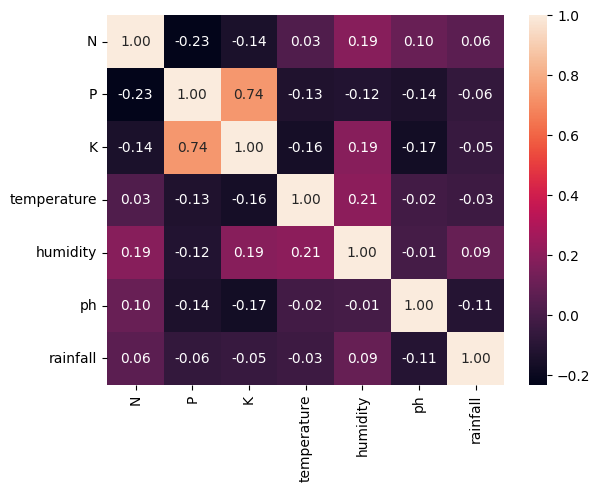

In [11]:
sns.heatmap(corr,annot=True,fmt='.2f')

In [12]:
data.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [13]:
data.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

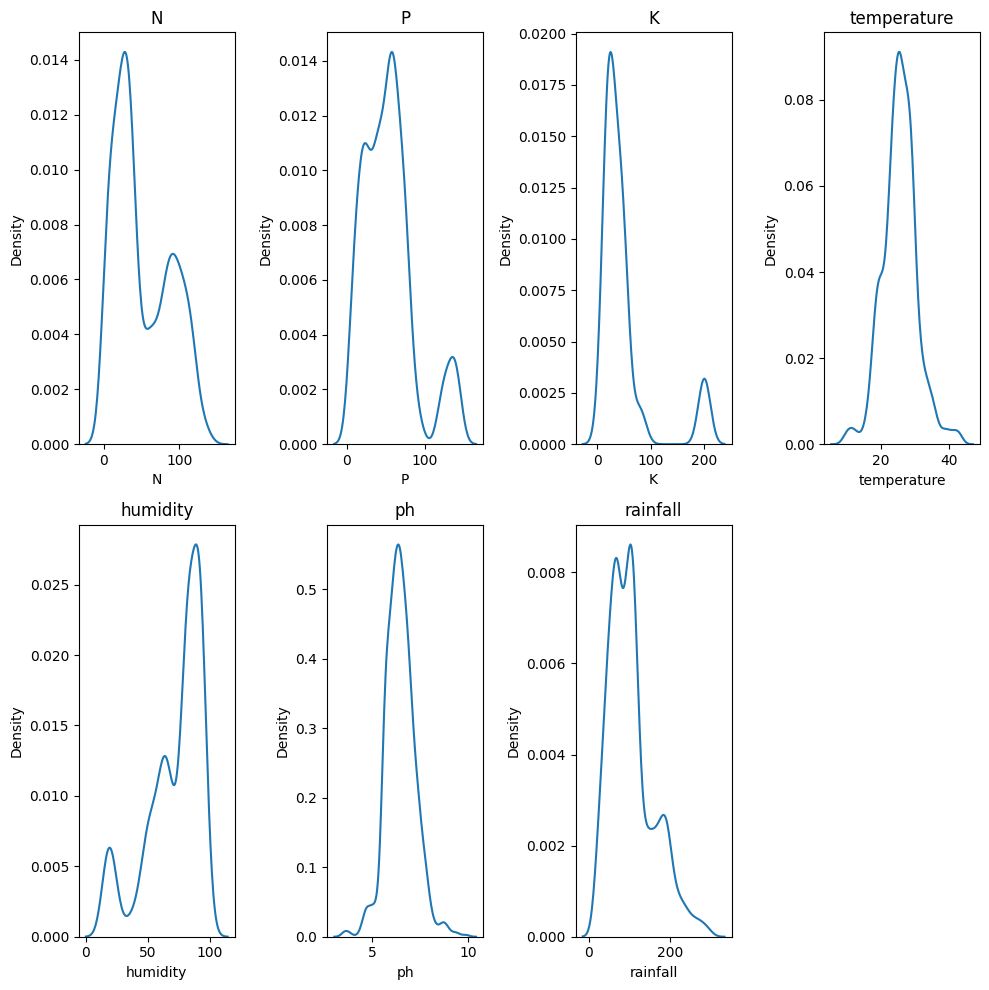

In [14]:
num=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

plt.figure(figsize=(10,10))
for index,col in enumerate(num):
  plt.subplot(2,4,index+1)
  sns.kdeplot(data[col])
  plt.title(col)
plt.tight_layout()
plt.show()

In [15]:
data['label'].value_counts().sort_values(ascending=False)

,count
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


<Axes: xlabel='count', ylabel='label'>

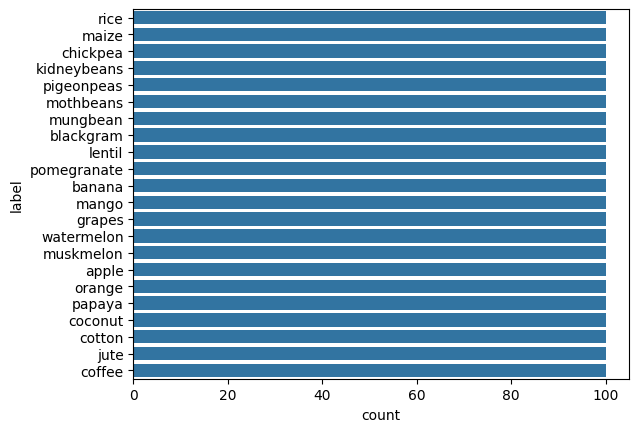

In [16]:
sns.countplot(data['label'])

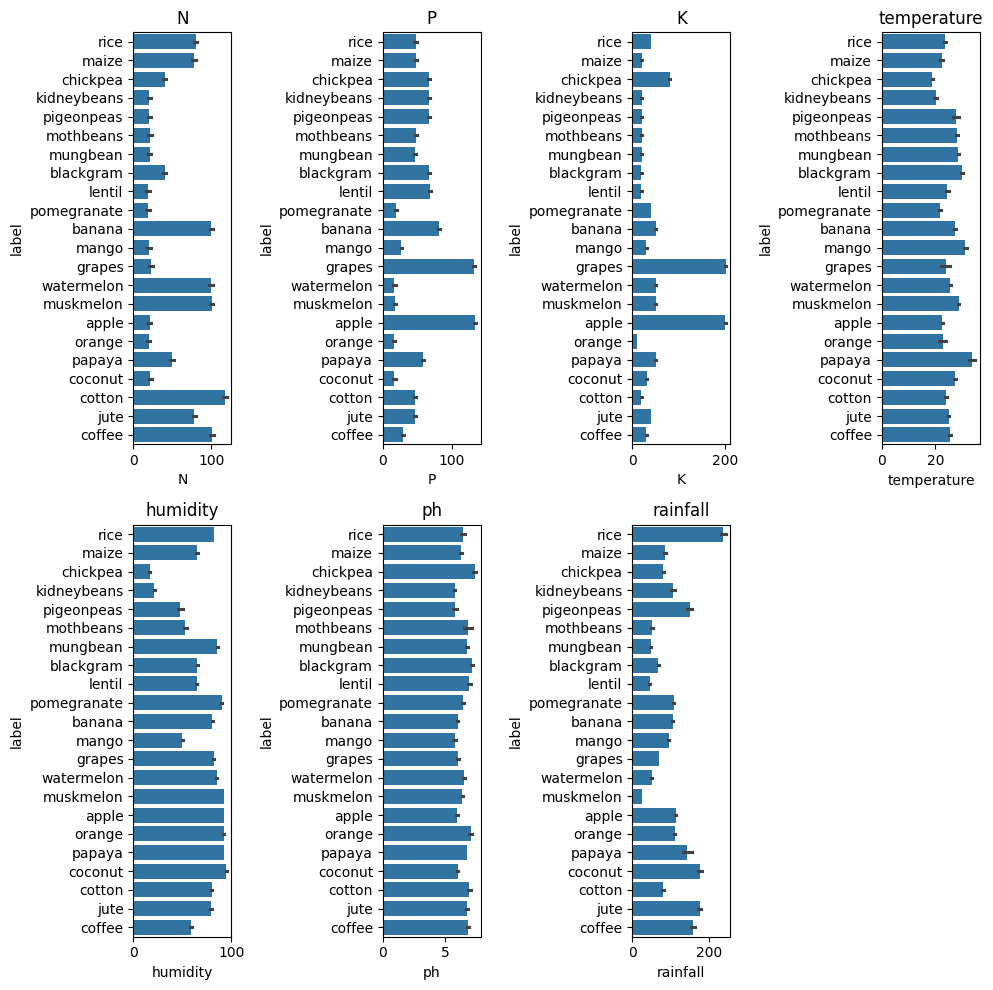

In [17]:
plt.figure(figsize=(10,10))
for index,col in enumerate(num):
  plt.subplot(2,4,index+1)
  sns.barplot(x=data[col],y=data['label'])
  plt.title(col)
plt.tight_layout()
plt.show()

In [18]:
x=data.drop(columns='label')

In [19]:
from sklearn.preprocessing import LabelEncoder


le = LabelEncoder()
y = le.fit_transform(data['label'])

In [20]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.2)

In [21]:
col=data.columns

In [22]:
col_input = col.drop('label')

In [23]:
clf = ColumnTransformer([
     ('scale', StandardScaler(), col_input)
])

In [24]:
pipe=Pipeline([
    ('clf',clf),
    ('boost',XGBClassifier())
])

In [25]:
pipe.fit(x_train, y_train)

Pipeline(steps=[('clf',
                 ColumnTransformer(transformers=[('scale', StandardScaler(),
                                                  Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'], dtype='object'))])),
                ('boost',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categori...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [26]:
y_pred=pipe.predict(x_test)

In [27]:
accuracy_score(y_pred,y_test)

0.9863636363636363

In [32]:
mtrx=confusion_matrix (y_test,y_pred)


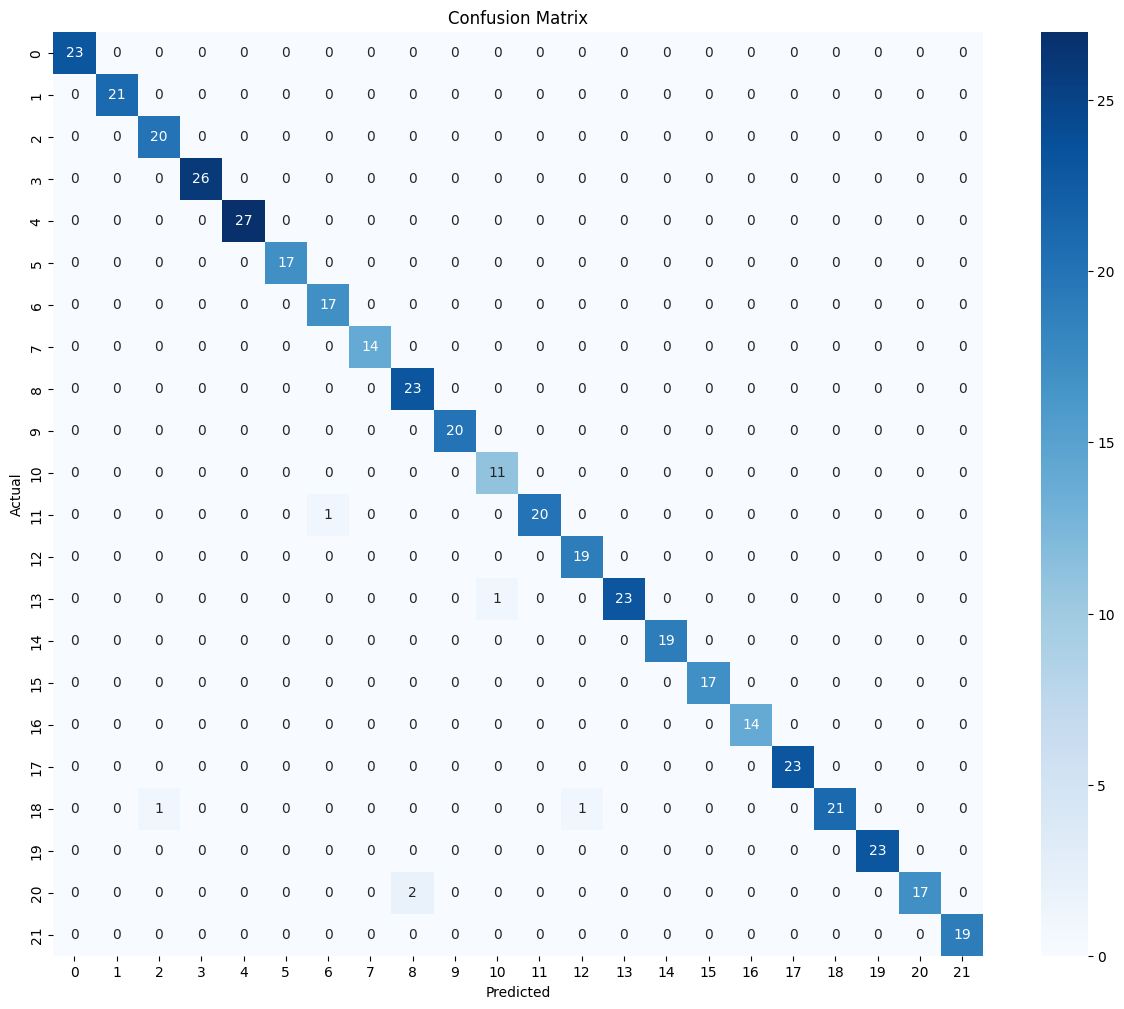

In [33]:
plt.figure(figsize=(15, 12))
sns.heatmap(mtrx, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [34]:

classes = le.classes_
stats = []

for i in range(len(classes)):
    tp = mtrx[i, i]
    fp = mtrx[:, i].sum() - tp
    fn = mtrx[i, :].sum() - tp
    tn = mtrx.sum() - (tp + fp + fn)

    stats.append({
        'Crop Class': classes[i],
        'True Positive (TP)': tp,
        'True Negative (TN)': tn,
        'False Positive (FP)': fp,
        'False Negative (FN)': fn
    })

multiclass_stats_df = pd.DataFrame(stats)
display(multiclass_stats_df)

,Crop Class,True Positive (TP),True Negative (TN),False Positive (FP),False Negative (FN)
0,apple,23,417,0,0
1,banana,21,419,0,0
2,blackgram,20,419,1,0
3,chickpea,26,414,0,0
4,coconut,27,413,0,0
5,coffee,17,423,0,0
6,cotton,17,422,1,0
7,grapes,14,426,0,0
8,jute,23,415,2,0
9,kidneybeans,20,420,0,0


In [35]:
import pickle


model_filename = 'crop_recommendation_pipeline.pkl'
encoder_filename = 'label_encoder.pkl'


with open(model_filename, 'wb') as model_file:
    pickle.dump(pipe, model_file)

with open(encoder_filename, 'wb') as encoder_file:
    pickle.dump(le, encoder_file)

print(f"Successfully saved model pipeline to: {model_filename}")
print(f"Successfully saved LabelEncoder to: {encoder_filename}")

Successfully saved model pipeline to: crop_recommendation_pipeline.pkl
Successfully saved LabelEncoder to: label_encoder.pkl
